# Task 04: Supervised Classification / Regression Modeling & Tuning

## 1. Objective
This notebook compares four supervised classification models for the actual `churned` target in `customer-churn-training.csv`. It uses reusable preprocessing, stratified cross-validation, small GridSearchCV parameter grids, held-out test evaluation, ROC-AUC curves, champion selection, error analysis, and serialization.

The dataset contains only 12 records. All validation and test metrics are educational and unstable; they must not be interpreted as production performance.

## 2. Load and Inspect Dataset
The notebook uses the existing CSV and identifies columns from the loaded data rather than inventing a schema.

## 3. Data Quality Checks
We inspect shape, columns, dtypes, missing values, duplicate rows, descriptive statistics, and the observed target distribution.

## 4. Define Features and Target
The actual `churned` column is the target. `customer_id` is excluded because it is an identifier, not a predictive feature.

## 5. Train/Test Split
The split happens before any preprocessing is fitted. Stratification and a fixed random state support reproducibility while preserving target classes as far as this small dataset permits.

## 6. Preprocessing Pipeline
Numerical values use median imputation and standardization. Categorical values use most-frequent imputation and one-hot encoding. The transformer is fitted only through each model Pipeline.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

In [2]:
# Resolve the existing dataset whether the notebook working directory is Task-04 or the project root.
dataset_path = Path.cwd() / "customer-churn-training.csv"
if not dataset_path.exists():
    dataset_path = Path.cwd().parent / "customer-churn-training.csv"
if not dataset_path.exists():
    raise FileNotFoundError("customer-churn-training.csv was not found in Task-04 or its parent project folder.")

data = pd.read_csv(dataset_path)
print(f"Loaded: {dataset_path}")
print(f"Dataset shape: {data.shape}")
print(f"Column names: {list(data.columns)}")
print("\nData types:")
print(data.dtypes)
print("\nFirst rows:")
display(data.head())

print("\nMissing values:")
print(data.isna().sum())
print(f"\nDuplicate rows: {data.duplicated().sum()}")
print("\nBasic descriptive statistics:")
display(data.select_dtypes(include="number").describe())

target_column = "churned"
if target_column not in data.columns:
    raise ValueError(f"Expected target {target_column!r} was not found in the actual columns.")
print("\nActual target distribution:")
print(data[target_column].value_counts().sort_index())

identifier_column = "customer_id"
excluded_columns = {target_column}
if identifier_column in data.columns:
    excluded_columns.add(identifier_column)
feature_columns = [column for column in data.columns if column not in excluded_columns]
X = data[feature_columns].copy()
y = data[target_column].copy()
categorical_features = X.select_dtypes(include=["str", "category", "bool"]).columns.tolist()
numerical_features = X.select_dtypes(include="number").columns.tolist()
print(f"\nNumerical features: {numerical_features}")
print(f"Categorical features: {categorical_features}")
print(f"customer_id excluded: {identifier_column not in X.columns}")
print(f"churned excluded from X: {target_column not in X.columns}")
if target_column in X.columns or identifier_column in X.columns:
    raise ValueError("Leakage check failed: target or identifier is present in X.")

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError("The actual target distribution cannot support a stratified split.")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"\nTraining shape: {X_train.shape}; test shape: {X_test.shape}")
print("Training target counts:")
print(y_train.value_counts().sort_index())
print("Test target counts:")
print(y_test.value_counts().sort_index())
print("Leakage check: preprocessing has not been fitted before this split.")

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")
print("Preprocessing is defined but has not been fitted independently.")

Loaded: c:\Users\user\Desktop\ML-Churn-Responsible-Project\customer-churn-training.csv
Dataset shape: (12, 7)
Column names: ['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']

Data types:
customer_id            str
tenure_months        int64
support_tickets      int64
monthly_spend_inr    int64
last_login_days      int64
plan_type              str
churned              int64
dtype: object

First rows:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0



Missing values:
customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate rows: 0

Basic descriptive statistics:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
count,12.000000,12.000000,12.000000,12.000000,12.000000
mean,12.166667,2.250000,915.666667,10.000000,0.416667
std,9.242524,1.602555,332.574895,9.095453,0.514929
min,1.000000,0.000000,499.000000,1.000000,0.000000
25%,5.500000,1.000000,724.000000,2.750000,0.000000
50%,9.500000,2.000000,899.000000,7.000000,0.000000
75%,18.500000,3.250000,1074.000000,14.750000,1.000000
max,30.000000,5.000000,1499.000000,30.000000,1.000000



Actual target distribution:
churned
0    7
1    5
Name: count, dtype: int64

Numerical features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']
Categorical features: ['plan_type']
customer_id excluded: True
churned excluded from X: True

Training shape: (9, 5); test shape: (3, 5)
Training target counts:
churned
0    5
1    4
Name: count, dtype: int64
Test target counts:
churned
0    2
1    1
Name: count, dtype: int64
Leakage check: preprocessing has not been fitted before this split.
Preprocessing is defined but has not been fitted independently.


## 7. Define Classification Models
Four distinct architectures are used: Logistic Regression, Random Forest, Support Vector Machine, and Gradient Boosting.

## 8. Stratified Cross-Validation
The fold count is based on the smallest class in the training split and capped at 3. This makes the CV feasible, but the folds remain very small and the estimates are unstable.

## 9. Hyperparameter Optimization
Each model uses a small GridSearchCV parameter grid, `scoring="f1"`, and the same StratifiedKFold strategy. The fitted preprocessing remains inside each Pipeline and each CV training fold.

In [3]:
random_state = 42
model_definitions = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=random_state),
        {"model__C": [0.1, 1.0, 10.0]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=random_state),
        {"model__n_estimators": [50, 100], "model__max_depth": [None, 3]},
    ),
    "Support Vector Machine": (
        SVC(probability=True, random_state=random_state),
        {"model__C": [0.5, 1.0], "model__kernel": ["linear", "rbf"]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=random_state),
        {"model__n_estimators": [50, 100], "model__learning_rate": [0.05, 0.1]},
    ),
}
print(f"Defined models: {list(model_definitions)}")

smallest_training_class = int(y_train.value_counts().min())
cv_folds = min(3, smallest_training_class)
if cv_folds < 2:
    raise ValueError("At least two records per training class are required for StratifiedKFold.")
cv_strategy = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
print(f"Using StratifiedKFold with {cv_folds} folds; smallest training class has {smallest_training_class} records.")
print("Warning: cross-validation estimates are unstable because the dataset and folds are very small.")

tuned_models = {}
tuning_rows = []
for model_name, (model, parameter_grid) in model_definitions.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ])
    search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=parameter_grid,
        scoring="f1",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    tuned_models[model_name] = search.best_estimator_
    tuning_rows.append({
        "Model": model_name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_,
    })
    print(f"{model_name}: best CV F1={search.best_score_:.3f}; params={search.best_params_}")

tuning_summary = pd.DataFrame(tuning_rows)
display(tuning_summary)

Defined models: ['Logistic Regression', 'Random Forest', 'Support Vector Machine', 'Gradient Boosting']
Using StratifiedKFold with 3 folds; smallest training class has 4 records.
Logistic Regression: best CV F1=1.000; params={'model__C': 1.0}
Random Forest: best CV F1=1.000; params={'model__max_depth': None, 'model__n_estimators': 50}


C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: best CV F1=1.000; params={'model__C': 0.5, 'model__kernel': 'linear'}
Gradient Boosting: best CV F1=1.000; params={'model__learning_rate': 0.05, 'model__n_estimators': 50}


,Model,Best CV F1,Best Parameters
0,Logistic Regression,1.0,{'model__C': 1.0}
1,Random Forest,1.0,"{'model__max_depth': None, 'model__n_estimator..."
2,Support Vector Machine,1.0,"{'model__C': 0.5, 'model__kernel': 'linear'}"
3,Gradient Boosting,1.0,"{'model__learning_rate': 0.05, 'model__n_estim..."


## 10. Model Comparison
The comparison table reports the best training-only CV F1 and every model's held-out test metrics.

## 11. ROC-AUC Curves
The curves use `predict_proba` when available and otherwise a decision score. Values are calculated from the actual held-out predictions.

## 12. Champion Model Selection
The champion is selected by highest mean CV F1. If there is a tie, mean CV ROC-AUC calculated within the training data is used as a secondary criterion only.

## 13. Confusion Matrix
A labeled confusion matrix is shown for the selected champion model.

,Model,Best CV F1,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0
2,Support Vector Machine,1.0,1.0,1.0,1.0,1.0
3,Gradient Boosting,1.0,1.0,1.0,1.0,1.0


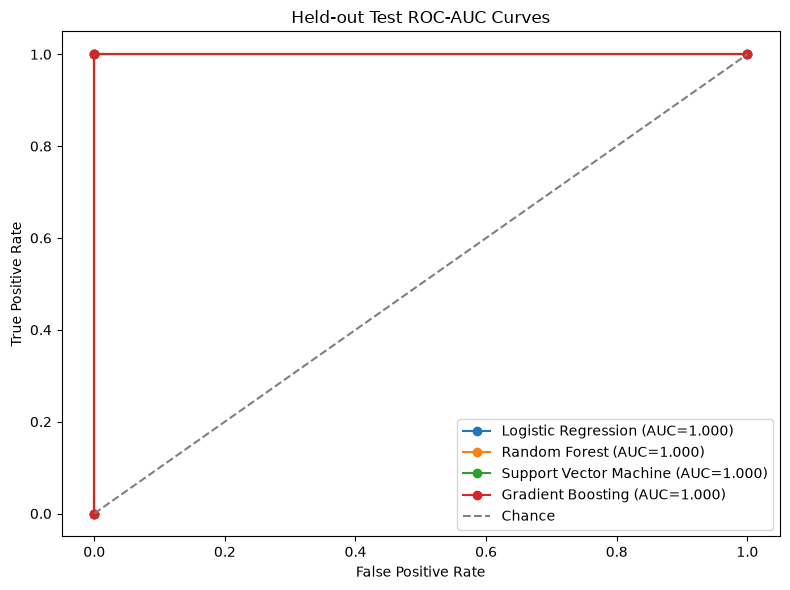

ROC-AUC values are calculated from model scores; no values are fabricated.
Tie on CV F1; secondary mean CV ROC-AUC values: {'Logistic Regression': np.float64(1.0), 'Random Forest': np.float64(1.0), 'Support Vector Machine': np.float64(1.0), 'Gradient Boosting': np.float64(1.0)}
Champion model selected by highest mean CV F1: Logistic Regression
Best parameters: {'model__C': 1.0}
Best mean CV F1: 1.000


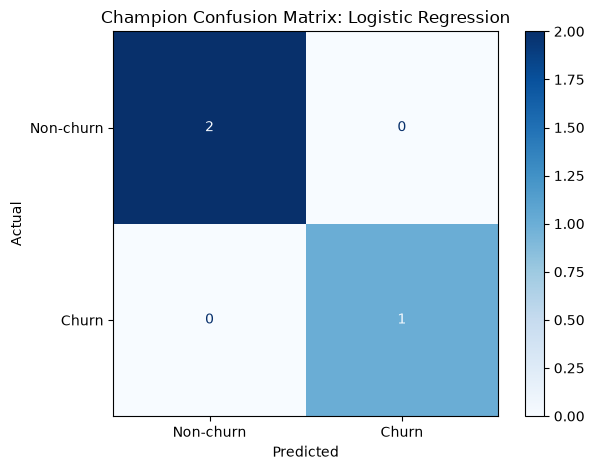

In [4]:
def get_score_values(fitted_model, features):
    if hasattr(fitted_model, "predict_proba"):
        return fitted_model.predict_proba(features)[:, 1]
    if hasattr(fitted_model, "decision_function"):
        return fitted_model.decision_function(features)
    return None

comparison_rows = []
test_scores = {}
for tuning_row in tuning_rows:
    model_name = tuning_row["Model"]
    fitted_model = tuned_models[model_name]
    predictions = fitted_model.predict(X_test)
    scores = get_score_values(fitted_model, X_test)
    test_scores[model_name] = scores
    comparison_rows.append({
        "Model": model_name,
        "Best CV F1": tuning_row["Best CV F1"],
        "Test Precision": precision_score(y_test, predictions, zero_division=0),
        "Test Recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1": f1_score(y_test, predictions, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, scores) if scores is not None else np.nan,
    })
model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison)
print("Warning: held-out test metrics are based on only a few records and may be unstable.")

plt.figure(figsize=(8, 6))
for model_name, scores in test_scores.items():
    if scores is not None:
        false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
        model_auc = auc(false_positive_rate, true_positive_rate)
        plt.plot(false_positive_rate, true_positive_rate, marker="o", label=f"{model_name} (AUC={model_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Held-out Test ROC-AUC Curves")
plt.legend()
plt.tight_layout()
plt.show()
print("ROC-AUC values are calculated from model scores; no values are fabricated.")

max_cv_f1 = model_comparison["Best CV F1"].max()
candidate_names = model_comparison.loc[model_comparison["Best CV F1"] == max_cv_f1, "Model"].tolist()
if len(candidate_names) > 1:
    cv_roc_auc_by_model = {
        name: cross_val_score(tuned_models[name], X_train, y_train, cv=cv_strategy, scoring="roc_auc", n_jobs=-1).mean()
        for name in candidate_names
    }
    champion_name = max(cv_roc_auc_by_model, key=cv_roc_auc_by_model.get)
    print(f"Tie on CV F1; secondary mean CV ROC-AUC values: {cv_roc_auc_by_model}")
else:
    champion_name = candidate_names[0]
champion_model = tuned_models[champion_name]
champion_parameters = next(row["Best Parameters"] for row in tuning_rows if row["Model"] == champion_name)
champion_cv_f1 = float(model_comparison.loc[model_comparison["Model"] == champion_name, "Best CV F1"].iloc[0])
print(f"Champion model selected by highest mean CV F1: {champion_name}")
print(f"Best parameters: {champion_parameters}")
print(f"Best mean CV F1: {champion_cv_f1:.3f}")

champion_predictions = champion_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    champion_predictions,
    labels=[0, 1],
    display_labels=["Non-churn", "Churn"],
    cmap="Blues",
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Champion Confusion Matrix: {champion_name}")
plt.tight_layout()
plt.show()

## 14. Final Test Evaluation
These metrics are calculated once for the selected champion on the untouched held-out test set and are separate from the CV score used for selection.

## 15. Error Analysis
False positives and false negatives are shown using only the available test records and actual dataset features.

## 16. Save Champion Model
The complete fitted Pipeline, including preprocessing, is saved as `Task-04/champion_model.joblib`.

In [5]:
champion_scores = get_score_values(champion_model, X_test)
final_test_metrics = {
    "Model": champion_name,
    "Held-out Test Precision": precision_score(y_test, champion_predictions, zero_division=0),
    "Held-out Test Recall": recall_score(y_test, champion_predictions, zero_division=0),
    "Held-out Test F1": f1_score(y_test, champion_predictions, zero_division=0),
    "Held-out Test ROC-AUC": roc_auc_score(y_test, champion_scores) if champion_scores is not None else np.nan,
}
display(pd.DataFrame([final_test_metrics]))
print("Final-test warning: the test set is extremely small, so these metrics are unstable.")

error_analysis = X_test.copy()
error_analysis["actual_churned"] = y_test
error_analysis["predicted_churned"] = champion_predictions
error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual_churned"] == 0) & (error_analysis["predicted_churned"] == 1),
        (error_analysis["actual_churned"] == 1) & (error_analysis["predicted_churned"] == 0),
    ],
    ["false_positive", "false_negative"],
    default="correct",
)
print("False positives:")
display(error_analysis[error_analysis["error_type"] == "false_positive"])
print("False negatives:")
display(error_analysis[error_analysis["error_type"] == "false_negative"])
print("Error analysis is highly limited because only a few test records are available.")

task4_directory = Path.cwd() if Path.cwd().name == "Task-04" else Path.cwd() / "Task-04"
model_output_path = task4_directory / "champion_model.joblib"
joblib.dump(champion_model, model_output_path)
print(f"Saved complete champion Pipeline to: {model_output_path}")
print(f"File exists: {model_output_path.exists()}")
if not model_output_path.exists():
    raise FileNotFoundError("The champion model file was not created.")

,Model,Held-out Test Precision,Held-out Test Recall,Held-out Test F1,Held-out Test ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0


Final-test warning: the test set is extremely small, so these metrics are unstable.
False positives:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,actual_churned,predicted_churned,error_type


False negatives:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,actual_churned,predicted_churned,error_type


Error analysis is highly limited because only a few test records are available.
Saved complete champion Pipeline to: c:\Users\user\Desktop\ML-Churn-Responsible-Project\Task-04\champion_model.joblib
File exists: True


## Additional Feature Analysis
Correlation analysis is shown for the actual numerical features using the training split. Mutual information is calculated on the transformed training data and aggregated back to the actual original features. Because only 9 training rows are available, these rankings are exploratory and not reliable evidence of feature importance.

In [6]:
print("Training numerical-feature correlation matrix:")
display(X_train[numerical_features].corr())

fitted_preprocessor = champion_model.named_steps["preprocessor"]
transformed_training = fitted_preprocessor.transform(X_train)
transformed_feature_names = fitted_preprocessor.get_feature_names_out()
discrete_flags = np.array([name.startswith("categorical__") for name in transformed_feature_names])
mutual_information = mutual_info_classif(
    transformed_training,
    y_train,
    discrete_features=discrete_flags,
    random_state=random_state,
)
mi_table = pd.DataFrame({
    "Transformed feature": transformed_feature_names,
    "Mutual information": mutual_information,
})
mi_table["Original feature"] = mi_table["Transformed feature"].map(
    lambda name: "plan_type" if name.startswith("categorical__plan_type_") else name.split("__", 1)[1]
)
feature_importance = (
    mi_table.groupby("Original feature", as_index=False)["Mutual information"]
    .max()
    .sort_values("Mutual information", ascending=False)
)
print("Exploratory mutual-information feature ranking:")
display(feature_importance)
print(f"Important features by this exploratory ranking: {feature_importance['Original feature'].tolist()}")
print("Limitation: with 9 training rows, these rankings are unstable and do not establish causation or fairness.")

Training numerical-feature correlation matrix:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days
tenure_months,1.000000,-0.929997,0.914543,-0.865168
support_tickets,-0.929997,1.000000,-0.843299,0.940636
monthly_spend_inr,0.914543,-0.843299,1.000000,-0.897597
last_login_days,-0.865168,0.940636,-0.897597,1.000000


Exploratory mutual-information feature ranking:


,Original feature,Mutual information
2,plan_type,0.686962
4,tenure_months,0.606746
3,support_tickets,0.497487
1,monthly_spend_inr,0.427116
0,last_login_days,0.411243


Important features by this exploratory ranking: ['plan_type', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']
Limitation: with 9 training rows, these rankings are unstable and do not establish causation or fairness.


## 17. Responsible ML and Limitations

### Limitations and Responsible Use

- The dataset has only 12 records and the held-out test set has very few records. Accuracy-related metrics, ROC-AUC, confusion matrices, and error analysis can change substantially when one row changes.
- Cross-validation uses small stratified folds because the smallest class in the training split determines the feasible fold count. Mean CV F1 is therefore an unstable estimate.
- The sampling process is not provided, so sampling bias and generalization to a wider customer population cannot be assessed. There is no independent external validation set.
- Preprocessing is fitted inside each Pipeline and GridSearchCV training fold after the train/test split. This prevents the notebook from fitting imputers, scalers, or encoders on held-out data, but feature timing and business definitions still require domain review.
- Mutual-information feature rankings are exploratory only. They are calculated from the transformed training rows, can vary with such a small sample, and do not establish causation, fairness, or a reason to exclude human judgment.
- The results are educational and must not be treated as production performance. Predictions should not automatically trigger customer actions. Human review would be required for real-world decisions, with privacy, fairness, and customer-impact safeguards.

## 18. Conclusion

This notebook provides a reproducible comparison of four tuned classification Pipelines using the actual customer-churn dataset. The champion label is conditional on the explicitly defined highest mean cross-validation F1 selection criterion, with training-only ROC-AUC as a tie-breaker. It is not a claim of universal superiority or deployment readiness.